# Phase 3 — Model Training, Evaluation & Selection

**Notebook:** `notebooks/model_training.ipynb`  ·  **Inputs:** `data/processed/train.csv`, `test.csv` (from Phase 2)
**Outputs:** `models/` (selected pipeline + metadata), `reports/` (comparison tables, logs, figures)

### Objectives (from `docs/plan.md`, Phase 3)
1. Train 8 candidates (a baseline plus 7 real models), all wrapped in the **same** Phase 2 preprocessing pipeline.
2. Compare them with stratified 5-fold CV on the training split, then lightly tune the top candidates.
3. Evaluate **performance** (accuracy, macro precision, recall, F1, top-3 accuracy) **and cost**
   (inference latency, model size, memory footprint).
4. Select the best model using the rule in `plan.md`, serialize it, and save evaluation logs.

### Context from Phase 2 (`docs/phase_logs.md`)
- 1,000 unique rows, 100 per crop; 800 train / 200 test, stratified, seed 42, no overlap between the two.
- Reference models already reached CV macro-F1 ≈ 1.0, and soil maps perfectly to crop groups.
  **Most models are expected to tie on accuracy.** That's why the plan's selection rule falls back to cost, and
  why this notebook also reports two supplementary signals: **log loss** (the quality of the confidence scores the
  app will display) and **robustness to measurement noise**.

| § | Section |
|---|---|
| 1 | Setup & data |
| 2 | Candidate models |
| 3 | Cross-validation (all candidates) |
| 4 | Hyperparameter tuning (top candidates) |
| 5 | Held-out test evaluation |
| 6 | Cost: latency, size, memory |
| 7 | Robustness to noisy inputs |
| 8 | Model selection |
| 9 | Selected model: diagnostics & feature importance |
| 10 | Serialize model & save logs |
| 11 | Summary |

## 1. Setup & data

In [1]:
from pathlib import Path
import json, os, platform, subprocess, sys, tempfile, time, warnings
from datetime import datetime, timezone

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from scipy.stats import loguniform, randint, uniform

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix, f1_score,
                             log_loss, make_scorer, precision_score, recall_score, top_k_accuracy_score)
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, cross_validate
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler
from sklearn.svm import SVC

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

# Optional gradient-boosting libraries. The plan requires both; the notebook reports clearly if one is missing.
try:
    import xgboost as xgb
    from xgboost import XGBClassifier
except ImportError:
    xgb = None
try:
    import lightgbm as lgb
    from lightgbm import LGBMClassifier
except ImportError:
    lgb = None
print("xgboost:", xgb.__version__ if xgb else "NOT INSTALLED", "| lightgbm:", lgb.__version__ if lgb else "NOT INSTALLED")

RANDOM_STATE = 42
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
MODELS_DIR = PROJECT_ROOT / "models"
REPORTS_DIR = PROJECT_ROOT / "reports"
FIG_DIR = REPORTS_DIR / "figures"
for d in (MODELS_DIR, REPORTS_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.precision", 4)

def save_fig(fig, name: str) -> None:
    fig.savefig(FIG_DIR / f"{name}.png", dpi=120, bbox_inches="tight")

xgboost: 3.4.1 | lightgbm: 4.7.0


In [2]:
prep_summary = json.loads((PROCESSED_DIR / "preprocessing_summary.json").read_text())
NUMERIC_FEATURES = prep_summary["numeric_features"]
CATEGORICAL_FEATURES = prep_summary["categorical_features"]
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES
TARGET = "crop_label"
assert prep_summary["keep_engineered_features"] is False  # Phase 2 decision: base inputs only

train_df = pd.read_csv(PROCESSED_DIR / "train.csv")
test_df = pd.read_csv(PROCESSED_DIR / "test.csv")

label_encoder = LabelEncoder().fit(prep_summary["classes"])
CLASSES = label_encoder.classes_.tolist()
X_train, y_train = train_df[FEATURES], label_encoder.transform(train_df[TARGET])
X_test, y_test = test_df[FEATURES], label_encoder.transform(test_df[TARGET])

print("Train:", X_train.shape, "| Test:", X_test.shape, "| classes:", len(CLASSES))
print("Train per class:", np.bincount(y_train).tolist())
print("Test per class: ", np.bincount(y_test).tolist())

Train: (800, 8) | Test: (200, 8) | classes: 10
Train per class: [80, 80, 80, 80, 80, 80, 80, 80, 80, 80]
Test per class:  [20, 20, 20, 20, 20, 20, 20, 20, 20, 20]


## 2. Candidate models
Every candidate is a `Pipeline(preprocessor → model)`, using the preprocessor designed in Phase 2. Training and
serving therefore apply identical transformations, and the saved file is fully self-contained.

- All models must support `predict_proba`, because the app shows the **top 3 crops with confidence scores**.
  `SVC` therefore uses `probability=True`.
- Each model uses `n_jobs=1` so that inference latency is measured fairly on a single core (that is how one app
  request runs). Cross-validation folds run in parallel instead.

In [3]:
def build_preprocessor() -> ColumnTransformer:
    # Phase 2 preprocessor: impute + scale numerics; impute + one-hot encode soil.
    numeric_pipe = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())])
    categorical_pipe = Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    return ColumnTransformer([("num", numeric_pipe, NUMERIC_FEATURES), ("cat", categorical_pipe, CATEGORICAL_FEATURES)])

def make_pipeline(model) -> Pipeline:
    return Pipeline([("prep", build_preprocessor()), ("model", model)])

def get_candidates() -> dict:
    # Default-configuration candidates. Tuned versions are produced in Section 4.
    models = {
        "Dummy (baseline)": DummyClassifier(strategy="stratified", random_state=RANDOM_STATE),
        "LogisticRegression": LogisticRegression(max_iter=5000, random_state=RANDOM_STATE),
        "KNN": KNeighborsClassifier(n_neighbors=5, n_jobs=1),
        "SVM (RBF)": SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE),
        "RandomForest": RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=1),
        "GradientBoosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
    }
    if xgb is not None:
        models["XGBoost"] = XGBClassifier(n_estimators=200, tree_method="hist", eval_metric="mlogloss",
                                          random_state=RANDOM_STATE, n_jobs=1)
    if lgb is not None:
        models["LightGBM"] = LGBMClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=1, verbose=-1)
    return {name: make_pipeline(m) for name, m in models.items()}

candidates = get_candidates()
missing = [m for m in ("XGBoost", "LightGBM") if m not in candidates]
print("Candidates:", list(candidates))
if missing:
    print(f"WARNING: {missing} skipped because the library is not installed. Install it and re-run for the full comparison.")

Candidates: ['Dummy (baseline)', 'LogisticRegression', 'KNN', 'SVM (RBF)', 'RandomForest', 'GradientBoosting', 'XGBoost', 'LightGBM']


## 3. Cross-validation (all candidates)
Stratified 5-fold CV on the **800 training rows only**. The test set stays untouched until Section 5.

| Metric | Why |
|---|---|
| Accuracy | Overall correctness |
| Macro precision, recall, F1 | All 10 crops weigh equally |
| Top-3 accuracy | The app shows 3 crops. Is the true crop among them? |
| Log loss | Quality of the probabilities shown as confidence scores (lower is better) |
| Fit time | Training cost |

In [4]:
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
LABELS = np.arange(len(CLASSES))
SCORING = {
    "accuracy": "accuracy",
    "precision_macro": make_scorer(precision_score, average="macro", zero_division=0),
    "recall_macro": make_scorer(recall_score, average="macro", zero_division=0),
    "f1_macro": make_scorer(f1_score, average="macro", zero_division=0),
    "top3_accuracy": make_scorer(top_k_accuracy_score, k=3, labels=LABELS, response_method="predict_proba"),
    "neg_log_loss": make_scorer(log_loss, greater_is_better=False, labels=LABELS, response_method="predict_proba"),
}

def run_cv(pipelines: dict) -> pd.DataFrame:
    rows = []
    for name, pipe in pipelines.items():
        res = cross_validate(pipe, X_train, y_train, cv=CV, scoring=SCORING, n_jobs=-1)
        row = {"model": name, "fit_time_s": res["fit_time"].mean()}
        for metric in SCORING:
            vals = res[f"test_{metric}"] * (-1 if metric.startswith("neg_") else 1)
            key = metric.replace("neg_", "")
            row[f"{key}_mean"], row[f"{key}_std"] = vals.mean(), vals.std()
        rows.append(row)
    return pd.DataFrame(rows).set_index("model").sort_values(["f1_macro_mean", "log_loss_mean"], ascending=[False, True])

t0 = time.perf_counter()
cv_results = run_cv(candidates)
print(f"CV finished in {time.perf_counter() - t0:.1f}s")
display(cv_results[["accuracy_mean", "precision_macro_mean", "recall_macro_mean", "f1_macro_mean",
                    "f1_macro_std", "top3_accuracy_mean", "log_loss_mean", "fit_time_s"]])

CV finished in 6.0s


,accuracy_mean,precision_macro_mean,recall_macro_mean,f1_macro_mean,f1_macro_std,top3_accuracy_mean,log_loss_mean,fit_time_s
model,,,,,,,,
KNN,1.0000,1.0000,1.0000,1.0000,0.0000,1.0000,2.2204e-16,0.0168
LogisticRegression,1.0000,1.0000,1.0000,1.0000,0.0000,1.0000,3.6569e-02,0.0310
SVM (RBF),1.0000,1.0000,1.0000,1.0000,0.0000,1.0000,9.6220e-02,0.0401
LightGBM,0.9988,0.9988,0.9988,0.9987,0.0025,1.0000,2.7936e-03,0.2925
RandomForest,0.9988,0.9988,0.9988,0.9987,0.0025,1.0000,8.3583e-03,0.3219
XGBoost,0.9988,0.9988,0.9988,0.9987,0.0025,1.0000,1.6120e-02,0.1745
GradientBoosting,0.9938,0.9942,0.9938,0.9937,0.0080,0.9975,1.2526e-02,1.4868
Dummy (baseline),0.0963,0.0951,0.0963,0.0950,0.0097,0.2975,3.2574e+01,0.0279


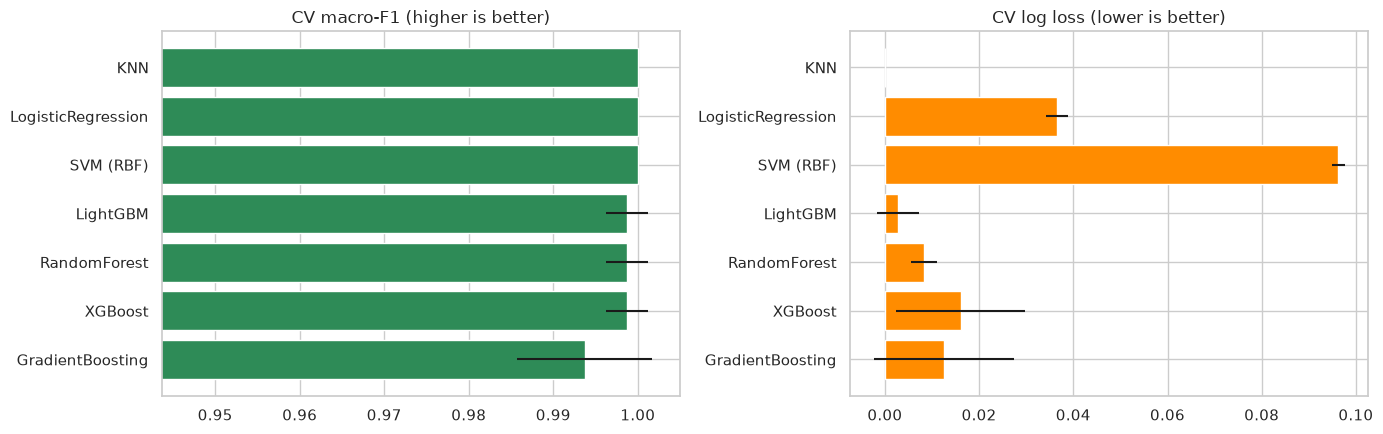

In [5]:
plot_df = cv_results.drop(index="Dummy (baseline)", errors="ignore")
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].barh(plot_df.index, plot_df["f1_macro_mean"], xerr=plot_df["f1_macro_std"], color="seagreen")
axes[0].set(title="CV macro-F1 (higher is better)", xlim=(max(0, plot_df["f1_macro_mean"].min() - 0.05), 1.005))
axes[1].barh(plot_df.index, plot_df["log_loss_mean"], xerr=plot_df["log_loss_std"], color="darkorange")
axes[1].set(title="CV log loss (lower is better)")
for ax in axes:
    ax.invert_yaxis()
fig.tight_layout()
save_fig(fig, "10_cv_comparison")
plt.show()

*Note on KNN:* its probabilities are vote shares among its neighbours, which are coarse (with 5 neighbours: 0, 0.2,
0.4 and so on). A log loss near 0 here means "every neighbour agreed", not that its confidence scores are finely
calibrated.

**Reading the results:** the Dummy baseline (random guessing in class proportions) scores about 0.10, which is the
floor. The gap between it and the real models confirms they learn real structure. As Phase 2 predicted, the real
models cluster at or near perfect F1. **Log loss** is where they differ: it shows how confident and well-calibrated each
model's probabilities are. That matters because the app displays these probabilities as confidence scores.

## 4. Hyperparameter tuning (top candidates)
"Top candidates" are the models within **1 percentage point of the best CV macro-F1**. If more than 4 qualify, we keep
the 4 with the lowest log loss. Because F1 is saturated, tuning optimises **log loss** (`neg_log_loss`), which improves
the confidence scores without hurting accuracy. The search is light: `RandomizedSearchCV`, 20 iterations, the same 5 folds.

In [6]:
PARAM_SPACES = {
    "LogisticRegression": {"model__C": loguniform(1e-2, 1e3)},
    "KNN": {"model__n_neighbors": randint(3, 31), "model__weights": ["uniform", "distance"]},
    "SVM (RBF)": {"model__C": loguniform(1e-1, 1e3), "model__gamma": loguniform(1e-3, 1e0)},
    "RandomForest": {"model__n_estimators": randint(100, 400), "model__max_depth": [None, 6, 10, 16],
                     "model__min_samples_leaf": randint(1, 5), "model__max_features": ["sqrt", "log2", None]},
    "GradientBoosting": {"model__n_estimators": randint(50, 200), "model__learning_rate": loguniform(0.02, 0.3),
                         "model__max_depth": randint(2, 5), "model__subsample": uniform(0.7, 0.3)},
    "XGBoost": {"model__n_estimators": randint(50, 300), "model__learning_rate": loguniform(0.02, 0.3),
                "model__max_depth": randint(2, 7), "model__subsample": uniform(0.7, 0.3),
                "model__colsample_bytree": uniform(0.6, 0.4)},
    "LightGBM": {"model__n_estimators": randint(50, 300), "model__learning_rate": loguniform(0.02, 0.3),
                 "model__num_leaves": randint(7, 40), "model__min_child_samples": randint(5, 30),
                 "model__subsample": uniform(0.7, 0.3), "model__subsample_freq": [1],
                 "model__colsample_bytree": uniform(0.6, 0.4)},
}

real = cv_results.drop(index="Dummy (baseline)")
best_f1 = real["f1_macro_mean"].max()
top = real[real["f1_macro_mean"] >= best_f1 - 0.01].sort_values("log_loss_mean").head(4)
TOP_CANDIDATES = top.index.tolist()
print(f"Best CV macro-F1 = {best_f1:.4f}; top candidates (within 1 pp, lowest log loss):", TOP_CANDIDATES)

Best CV macro-F1 = 1.0000; top candidates (within 1 pp, lowest log loss): ['KNN', 'LightGBM', 'RandomForest', 'GradientBoosting']


In [7]:
tuned_pipelines, tuning_log = {}, []
for name in TOP_CANDIDATES:
    search = RandomizedSearchCV(candidates[name], PARAM_SPACES[name], n_iter=20, cv=CV, scoring="neg_log_loss",
                                n_jobs=-1, random_state=RANDOM_STATE, refit=True)
    t0 = time.perf_counter()
    search.fit(X_train, y_train)
    default_ll = cv_results.loc[name, "log_loss_mean"]
    tuning_log.append({"model": name, "default_cv_log_loss": default_ll, "tuned_cv_log_loss": -search.best_score_,
                       "search_time_s": time.perf_counter() - t0,
                       "best_params": {k.replace("model__", ""): (v.item() if hasattr(v, "item") else v)
                                       for k, v in search.best_params_.items()}})
    # Keep the tuned version only if it actually improved CV log loss.
    tuned_pipelines[f"{name} (tuned)"] = search.best_estimator_ if -search.best_score_ < default_ll else candidates[name]

tuning_df = pd.DataFrame(tuning_log).set_index("model")
display(tuning_df)

,default_cv_log_loss,tuned_cv_log_loss,search_time_s,best_params
model,,,,
KNN,2.2204e-16,2.2204e-16,0.5041,"{'n_neighbors': 5, 'weights': 'distance'}"
LightGBM,2.7936e-03,4.7654e-04,6.2363,"{'colsample_bytree': 0.7085396127095583, 'lear..."
RandomForest,8.3583e-03,7.2297e-03,9.8167,"{'max_depth': 16, 'max_features': None, 'min_s..."
GradientBoosting,1.2526e-02,1.8314e-03,32.0203,"{'learning_rate': 0.10480691345771218, 'max_de..."


In [8]:
# Re-run the full CV metric set on the tuned pipelines so they are directly comparable with Section 3.
tuned_cv = run_cv(tuned_pipelines)
cv_all = pd.concat([cv_results, tuned_cv]).sort_values(["f1_macro_mean", "log_loss_mean"], ascending=[False, True])
cv_all.to_csv(REPORTS_DIR / "cv_results.csv")
display(cv_all[["f1_macro_mean", "f1_macro_std", "top3_accuracy_mean", "log_loss_mean", "fit_time_s"]])

,f1_macro_mean,f1_macro_std,top3_accuracy_mean,log_loss_mean,fit_time_s
model,,,,,
KNN,1.0000,0.0000,1.0000,2.2204e-16,0.0168
KNN (tuned),1.0000,0.0000,1.0000,2.2204e-16,0.0126
LightGBM (tuned),1.0000,0.0000,1.0000,4.7654e-04,0.1808
LogisticRegression,1.0000,0.0000,1.0000,3.6569e-02,0.0310
SVM (RBF),1.0000,0.0000,1.0000,9.6220e-02,0.0401
GradientBoosting (tuned),0.9987,0.0025,1.0000,1.8314e-03,1.6495
LightGBM,0.9987,0.0025,1.0000,2.7936e-03,0.2925
RandomForest (tuned),0.9987,0.0025,1.0000,7.2297e-03,0.7602
RandomForest,0.9987,0.0025,1.0000,8.3583e-03,0.3219


## 5. Held-out test evaluation
Every default and tuned model is refitted on all 800 training rows and scored **once** on the 200 test rows.
Test results are reported for transparency. **Selection (Section 8) uses CV and cost**, not the test set, so the test
score stays an unbiased estimate.

In [9]:
all_pipelines = {**candidates, **tuned_pipelines}
fitted, test_rows = {}, []
for name, pipe in all_pipelines.items():
    t0 = time.perf_counter()
    model = sklearn.base.clone(pipe).fit(X_train, y_train)
    fit_s = time.perf_counter() - t0
    proba = model.predict_proba(X_test)
    pred = proba.argmax(axis=1)
    fitted[name] = model
    test_rows.append({
        "model": name,
        "test_accuracy": accuracy_score(y_test, pred),
        "test_precision_macro": precision_score(y_test, pred, average="macro", zero_division=0),
        "test_recall_macro": recall_score(y_test, pred, average="macro", zero_division=0),
        "test_f1_macro": f1_score(y_test, pred, average="macro", zero_division=0),
        "test_top3_accuracy": top_k_accuracy_score(y_test, proba, k=3, labels=LABELS),
        "test_log_loss": log_loss(y_test, proba, labels=LABELS),
        "full_fit_time_s": fit_s,
    })
test_results = pd.DataFrame(test_rows).set_index("model")
display(test_results.sort_values(["test_f1_macro", "test_log_loss"], ascending=[False, True]))

,test_accuracy,test_precision_macro,test_recall_macro,test_f1_macro,test_top3_accuracy,test_log_loss,full_fit_time_s
model,,,,,,,
KNN,1.0,1.000,1.0,1.0000,1.00,2.2204e-16,0.0114
KNN (tuned),1.0,1.000,1.0,1.0000,1.00,2.2204e-16,0.0076
GradientBoosting (tuned),1.0,1.000,1.0,1.0000,1.00,2.3142e-08,1.1146
GradientBoosting,1.0,1.000,1.0,1.0000,1.00,3.8318e-08,1.2182
LightGBM,1.0,1.000,1.0,1.0000,1.00,1.0179e-05,0.2548
LightGBM (tuned),1.0,1.000,1.0,1.0000,1.00,1.0200e-05,0.1219
RandomForest (tuned),1.0,1.000,1.0,1.0000,1.00,2.2167e-03,0.5138
RandomForest,1.0,1.000,1.0,1.0000,1.00,3.7051e-03,0.2471
XGBoost,1.0,1.000,1.0,1.0000,1.00,6.6087e-03,0.1259


## 6. Cost: latency, size, memory
Measured on each fully fitted pipeline:

| Metric | Method |
|---|---|
| **Single-row latency** | `predict_proba` on 1 row (one app request), median of 300 runs after warm-up |
| **Batch latency** | `predict_proba` on 1,000 rows, median of 30 runs, reported per 1,000 rows |
| **Model size** | `joblib` file on disk (compress=3), in KB |
| **Load time** | Time for `joblib.load` in a fresh Python process |
| **Memory footprint** | In a **separate fresh Python process** (numpy, pandas and scikit-learn already imported): load the model and predict on 1 row and on 1,000 rows. We record (a) the peak of Python/NumPy allocations via `tracemalloc` and (b) the growth in process RSS via `psutil`, which also captures native C/C++ memory such as XGBoost/LightGBM libraries that `tracemalloc` misses. `peak_memory_mb` = the larger of the two. |

Absolute numbers depend on this machine. The **relative** ranking is what matters.

*Reading the memory column:* even the Dummy baseline grows RSS by about 20 MB. That is a shared floor: the first
`predict_proba` call loads scikit-learn's lazily imported modules. What separates models is the amount **above** that floor.

In [10]:
single_row = X_test.iloc[[0]]
batch = X_test.sample(1000, replace=True, random_state=RANDOM_STATE)

def median_latency_ms(fn, runs: int, warmup: int = 10) -> float:
    for _ in range(warmup):
        fn()
    times = []
    for _ in range(runs):
        t0 = time.perf_counter()
        fn()
        times.append((time.perf_counter() - t0) * 1000)
    return float(np.median(times))

# Script run in a fresh interpreter: measures load time and extra peak RSS for load + predict.
# argv: model path, data path, mode ("time" = load time only; "mem" = memory with tracemalloc on).
MEM_PROBE = r'''
import gc, json, sys, time, tracemalloc
import numpy, pandas, sklearn, joblib, psutil
proc = psutil.Process()
X = pandas.read_csv(sys.argv[2])
gc.collect()
if sys.argv[3] == "time":
    t0 = time.perf_counter()
    joblib.load(sys.argv[1])
    print(json.dumps({"load_s": time.perf_counter() - t0}))
else:
    base_rss = proc.memory_info().rss
    tracemalloc.start()
    model = joblib.load(sys.argv[1])
    model.predict_proba(X.iloc[[0]]); model.predict_proba(X)
    _, py_peak = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    rss_delta = proc.memory_info().rss - base_rss
    print(json.dumps({"py_peak_mb": py_peak / 2**20, "rss_delta_mb": max(rss_delta, 0) / 2**20}))
'''

def run_probe(model_path: Path, data_path: Path, mode: str) -> dict:
    out = subprocess.run([sys.executable, "-c", MEM_PROBE, str(model_path), str(data_path), mode],
                         capture_output=True, text=True, check=True)
    return json.loads(out.stdout.strip().splitlines()[-1])

def subprocess_memory(model_path: Path, data_path: Path, repeats: int = 3) -> dict:
    # Median over a few fresh processes to smooth out OS noise.
    loads = [run_probe(model_path, data_path, "time")["load_s"] for _ in range(repeats)]
    mems = [run_probe(model_path, data_path, "mem") for _ in range(repeats)]
    return {"load_s": float(np.median(loads)),
            "py_peak_mb": float(np.median([m["py_peak_mb"] for m in mems])),
            "rss_delta_mb": float(np.median([m["rss_delta_mb"] for m in mems]))}

cost_rows = []
with tempfile.TemporaryDirectory() as tmp:
    tmp = Path(tmp)
    batch_path = tmp / "batch.csv"
    batch.to_csv(batch_path, index=False)
    for name, model in fitted.items():
        path = tmp / "model.joblib"
        joblib.dump(model, path, compress=3)
        mem = subprocess_memory(path, batch_path)
        cost_rows.append({
            "model": name,
            "latency_single_ms": median_latency_ms(lambda: model.predict_proba(single_row), runs=300),
            "latency_batch1k_ms": median_latency_ms(lambda: model.predict_proba(batch), runs=30, warmup=3),
            "size_kb": path.stat().st_size / 1024,
            "load_time_ms": mem["load_s"] * 1000,
            "py_alloc_peak_mb": mem["py_peak_mb"],
            "rss_growth_mb": mem["rss_delta_mb"],
            "peak_memory_mb": max(mem["py_peak_mb"], mem["rss_delta_mb"]),
        })
cost_results = pd.DataFrame(cost_rows).set_index("model")
display(cost_results.sort_values("latency_single_ms"))

,latency_single_ms,latency_batch1k_ms,size_kb,load_time_ms,py_alloc_peak_mb,rss_growth_mb,peak_memory_mb
model,,,,,,,
SVM (RBF),2.7553,12.3938,18.2158,62.1335,9.1184,20.4336,20.4336
Dummy (baseline),2.7573,3.1519,1.7871,62.8825,9.1373,20.5352,20.5352
LogisticRegression,2.7781,3.0956,2.9375,60.7763,9.1487,20.5742,20.5742
KNN (tuned),3.0398,7.2115,62.9316,62.9773,9.3776,20.8867,20.8867
KNN,3.1193,7.2916,62.9316,62.2607,9.3768,20.9023,20.9023
XGBoost,3.2334,10.3571,65.1475,92.9509,12.9701,41.4023,41.4023
LightGBM,3.2930,28.2800,696.9775,92.7796,13.9273,30.1055,30.1055
LightGBM (tuned),3.3089,18.6760,281.4873,83.7842,11.6077,28.2148,28.2148
GradientBoosting (tuned),3.7117,15.2474,193.9473,143.9822,17.8141,36.5039,36.5039


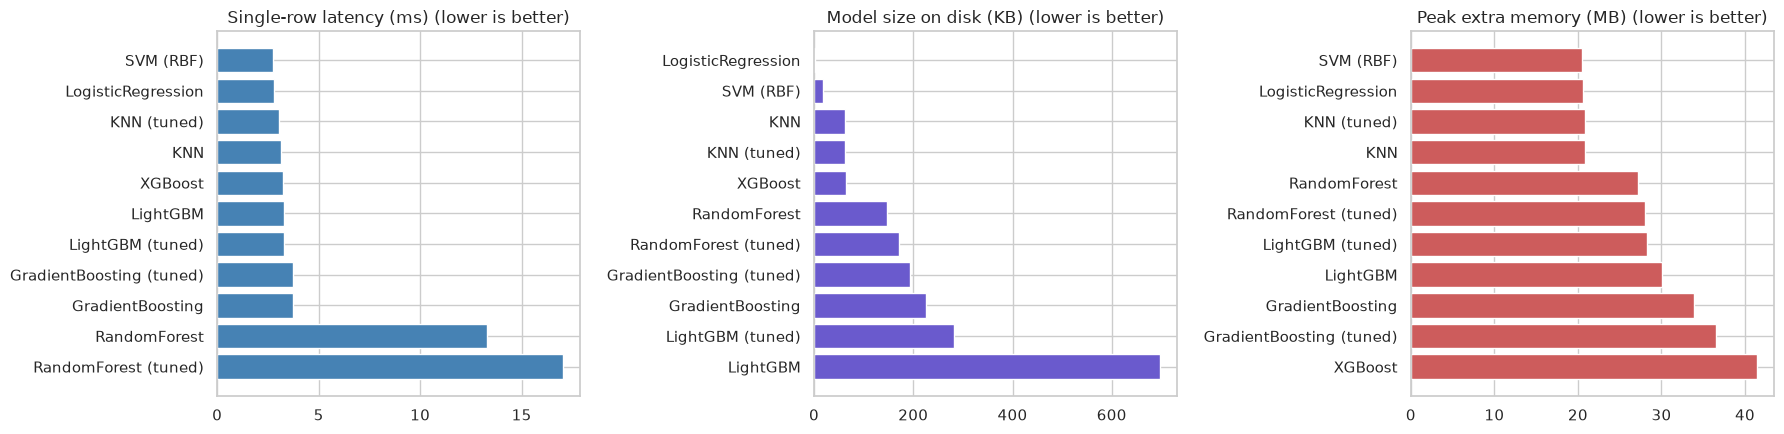

In [11]:
cplot = cost_results.drop(index="Dummy (baseline)")
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, col, title, color in zip(axes, ["latency_single_ms", "size_kb", "peak_memory_mb"],
                                 ["Single-row latency (ms)", "Model size on disk (KB)", "Peak extra memory (MB)"],
                                 ["steelblue", "slateblue", "indianred"]):
    s = cplot[col].sort_values()
    ax.barh(s.index, s.values, color=color)
    ax.set_title(title + " (lower is better)")
    ax.invert_yaxis()
fig.tight_layout()
save_fig(fig, "11_cost_comparison")
plt.show()

## 7. Robustness to noisy inputs
Real soil reports carry measurement and rounding error. To see whether a model's near-perfect accuracy survives small
errors, we add Gaussian noise to the **numeric** test features (5 %, 10 % and 20 % of each feature's training standard
deviation, 20 repetitions each) and measure accuracy and top-3 accuracy. Soil is left unchanged. This is a supplementary
signal: it can flag a fragile model, but the selection rule in `plan.md` is unchanged.

In [12]:
rng = np.random.default_rng(RANDOM_STATE)
train_std = X_train[NUMERIC_FEATURES].std()
NOISE_LEVELS, REPEATS = [0.05, 0.10, 0.20], 20
noisy_sets = {lvl: [] for lvl in NOISE_LEVELS}
for lvl in NOISE_LEVELS:
    for _ in range(REPEATS):
        Xn = X_test.copy()
        Xn[NUMERIC_FEATURES] = Xn[NUMERIC_FEATURES] + rng.normal(0, 1, (len(Xn), len(NUMERIC_FEATURES))) * (lvl * train_std.values)
        noisy_sets[lvl].append(Xn)

robust_rows = []
for name, model in fitted.items():
    row = {"model": name}
    for lvl in NOISE_LEVELS:
        accs, top3s = [], []
        for Xn in noisy_sets[lvl]:
            proba = model.predict_proba(Xn)
            accs.append(accuracy_score(y_test, proba.argmax(axis=1)))
            top3s.append(top_k_accuracy_score(y_test, proba, k=3, labels=LABELS))
        row[f"acc_noise_{int(lvl*100)}pct"] = np.mean(accs)
        row[f"top3_noise_{int(lvl*100)}pct"] = np.mean(top3s)
    robust_rows.append(row)
robust_results = pd.DataFrame(robust_rows).set_index("model")
display(robust_results.sort_values("acc_noise_20pct", ascending=False))

,acc_noise_5pct,top3_noise_5pct,acc_noise_10pct,top3_noise_10pct,acc_noise_20pct,top3_noise_20pct
model,,,,,,
SVM (RBF),1.0000,1.0000,1.0000,1.0000,0.9998,1.0000
LogisticRegression,1.0000,1.0000,1.0000,1.0000,0.9995,1.0000
KNN,1.0000,1.0000,1.0000,1.0000,0.9990,1.0000
KNN (tuned),1.0000,1.0000,1.0000,1.0000,0.9990,1.0000
RandomForest,0.9985,1.0000,0.9935,1.0000,0.9830,1.0000
RandomForest (tuned),0.9963,1.0000,0.9892,0.9995,0.9762,0.9957
LightGBM (tuned),0.9980,1.0000,0.9903,0.9998,0.9565,0.9940
GradientBoosting (tuned),0.9942,0.9970,0.9807,0.9887,0.9388,0.9623
LightGBM,0.9937,0.9972,0.9770,0.9887,0.9240,0.9693


## 8. Model selection
**Rule (from `docs/plan.md`):** highest CV macro-F1. If several models are within about 1 percentage point, choose the
**cheapest**.

How "cheapest" is made concrete here:
1. **Shortlist:** models within 1 pp of the best CV macro-F1 (Dummy excluded).
2. **Quality guards** (supplementary, so a cheap model can't be fragile or overconfident):
   - accuracy under 10 % noise must be within 2 pp of the best shortlisted model;
   - CV log loss must be at most 0.15, i.e. reasonable confidence scores.
3. **Cost rank:** rank the remaining models on single-row latency, size and peak memory (1 = cheapest), and
   pick the lowest sum of ranks. Differences of a few microseconds or bytes are noise, not real cost, so values
   **within 10 % of each other share a rank** (a tolerance band). Ties go to the lower CV log loss, i.e. better
   confidence scores.

In [13]:
comparison = (cv_all[["accuracy_mean", "precision_macro_mean", "recall_macro_mean", "f1_macro_mean", "f1_macro_std",
                      "top3_accuracy_mean", "log_loss_mean", "fit_time_s"]]
              .add_prefix("cv_").rename(columns=lambda c: c.replace("_mean", ""))
              .join(test_results).join(cost_results).join(robust_results))

shortlist = comparison.drop(index="Dummy (baseline)")
best_cv_f1 = shortlist["cv_f1_macro"].max()
shortlist = shortlist[shortlist["cv_f1_macro"] >= best_cv_f1 - 0.01].copy()
best_noise = shortlist["acc_noise_10pct"].max()
shortlist["passes_noise_guard"] = shortlist["acc_noise_10pct"] >= best_noise - 0.02
shortlist["passes_logloss_guard"] = shortlist["cv_log_loss"] <= 0.15
eligible = shortlist[shortlist["passes_noise_guard"] & shortlist["passes_logloss_guard"]].copy()
if eligible.empty:  # fall back to the shortlist rather than fail
    eligible = shortlist.copy()

def tolerant_rank(values: pd.Series, rel_tol: float = 0.10, abs_floor: float = 0.0) -> pd.Series:
    # Dense rank where each value within rel_tol (or abs_floor) of its group's smallest value shares that rank.
    ranks, rank, group_min = {}, 0, None
    for idx, v in values.sort_values().items():
        if group_min is None or v > max(group_min * (1 + rel_tol), group_min + abs_floor):
            rank, group_min = rank + 1, v
        ranks[idx] = rank
    return pd.Series(ranks).reindex(values.index)

COST_TOLERANCE_FLOORS = {"latency_single_ms": 0.1, "size_kb": 1.0, "peak_memory_mb": 0.5}
for col, floor in COST_TOLERANCE_FLOORS.items():
    eligible[f"rank_{col}"] = tolerant_rank(eligible[col], abs_floor=floor)
eligible["cost_rank_sum"] = eligible[[c for c in eligible if c.startswith("rank_")]].sum(axis=1)
eligible = eligible.sort_values(["cost_rank_sum", "cv_log_loss"])

SELECTED = eligible.index[0]
display(shortlist[["cv_f1_macro", "cv_log_loss", "acc_noise_10pct", "passes_noise_guard", "passes_logloss_guard"]])
display(eligible[["cv_f1_macro", "cv_log_loss", "latency_single_ms", "size_kb", "peak_memory_mb", "cost_rank_sum"]])
print("SELECTED MODEL:", SELECTED)

,cv_f1_macro,cv_log_loss,acc_noise_10pct,passes_noise_guard,passes_logloss_guard
model,,,,,
KNN,1.0000,2.2204e-16,1.0000,True,True
KNN (tuned),1.0000,2.2204e-16,1.0000,True,True
LightGBM (tuned),1.0000,4.7654e-04,0.9903,True,True
LogisticRegression,1.0000,3.6569e-02,1.0000,True,True
SVM (RBF),1.0000,9.6220e-02,1.0000,True,True
GradientBoosting (tuned),0.9987,1.8314e-03,0.9807,True,True
LightGBM,0.9987,2.7936e-03,0.9770,False,True
RandomForest (tuned),0.9987,7.2297e-03,0.9892,True,True
RandomForest,0.9987,8.3583e-03,0.9935,True,True


,cv_f1_macro,cv_log_loss,latency_single_ms,size_kb,peak_memory_mb,cost_rank_sum
model,,,,,,
LogisticRegression,1.0000,3.6569e-02,2.7781,2.9375,20.5742,3
SVM (RBF),1.0000,9.6220e-02,2.7553,18.2158,20.4336,4
KNN,1.0000,2.2204e-16,3.1193,62.9316,20.9023,6
KNN (tuned),1.0000,2.2204e-16,3.0398,62.9316,20.8867,6
RandomForest,0.9987,8.3583e-03,13.2708,146.7402,27.1562,10
LightGBM (tuned),1.0000,4.7654e-04,3.3089,281.4873,28.2148,11
GradientBoosting (tuned),0.9987,1.8314e-03,3.7117,193.9473,36.5039,12
RandomForest (tuned),0.9987,7.2297e-03,17.0401,171.2998,28.0273,12


SELECTED MODEL: LogisticRegression


In [14]:
comparison["selected"] = comparison.index == SELECTED
comparison.sort_values(["cv_f1_macro", "cv_log_loss"], ascending=[False, True]).to_csv(REPORTS_DIR / "model_comparison.csv")
display(comparison.sort_values(["cv_f1_macro", "cv_log_loss"], ascending=[False, True])[
    ["cv_f1_macro", "cv_top3_accuracy", "cv_log_loss", "test_f1_macro", "test_top3_accuracy",
     "latency_single_ms", "size_kb", "peak_memory_mb", "acc_noise_10pct", "selected"]])

,cv_f1_macro,cv_top3_accuracy,cv_log_loss,test_f1_macro,test_top3_accuracy,latency_single_ms,size_kb,peak_memory_mb,acc_noise_10pct,selected
model,,,,,,,,,,
KNN,1.0000,1.0000,2.2204e-16,1.0000,1.00,3.1193,62.9316,20.9023,1.0000,False
KNN (tuned),1.0000,1.0000,2.2204e-16,1.0000,1.00,3.0398,62.9316,20.8867,1.0000,False
LightGBM (tuned),1.0000,1.0000,4.7654e-04,1.0000,1.00,3.3089,281.4873,28.2148,0.9903,False
LogisticRegression,1.0000,1.0000,3.6569e-02,1.0000,1.00,2.7781,2.9375,20.5742,1.0000,True
SVM (RBF),1.0000,1.0000,9.6220e-02,1.0000,1.00,2.7553,18.2158,20.4336,1.0000,False
GradientBoosting (tuned),0.9987,1.0000,1.8314e-03,1.0000,1.00,3.7117,193.9473,36.5039,0.9807,False
LightGBM,0.9987,1.0000,2.7936e-03,1.0000,1.00,3.2930,696.9775,30.1055,0.9770,False
RandomForest (tuned),0.9987,1.0000,7.2297e-03,1.0000,1.00,17.0401,171.2998,28.0273,0.9892,False
RandomForest,0.9987,1.0000,8.3583e-03,1.0000,1.00,13.2708,146.7402,27.1562,0.9935,False


In [15]:
sel = comparison.loc[SELECTED]
runner_up = eligible.index[1] if len(eligible) > 1 else None
rationale = (
    f"{SELECTED} was selected. CV macro-F1 = {sel.cv_f1_macro:.4f} (best = {best_cv_f1:.4f}); "
    f"{len(shortlist)} models were within 1 pp, so the cost rule decided. Among those passing the noise and "
    f"log-loss guards, {SELECTED} had the lowest cost rank sum "
    f"(single-row latency {sel.latency_single_ms:.2f} ms, size {sel.size_kb:.1f} KB, "
    f"peak memory {sel.peak_memory_mb:.1f} MB). Held-out test: macro-F1 {sel.test_f1_macro:.4f}, "
    f"top-3 accuracy {sel.test_top3_accuracy:.4f}, log loss {sel.test_log_loss:.4f}; "
    f"accuracy under 10% input noise {sel.acc_noise_10pct:.4f}."
    + (f" Runner-up: {runner_up}." if runner_up else "")
)
print(rationale)

LogisticRegression was selected. CV macro-F1 = 1.0000 (best = 1.0000); 11 models were within 1 pp, so the cost rule decided. Among those passing the noise and log-loss guards, LogisticRegression had the lowest cost rank sum (single-row latency 2.78 ms, size 2.9 KB, peak memory 20.6 MB). Held-out test: macro-F1 1.0000, top-3 accuracy 1.0000, log loss 0.0326; accuracy under 10% input noise 1.0000. Runner-up: SVM (RBF).


## 9. Selected model: diagnostics & feature importance

              precision    recall  f1-score   support

       beans     1.0000    1.0000    1.0000        20
     cassava     1.0000    1.0000    1.0000        20
 guinea_corn     1.0000    1.0000    1.0000        20
       maize     1.0000    1.0000    1.0000        20
      orange     1.0000    1.0000    1.0000        20
      pepper     1.0000    1.0000    1.0000        20
        rice     1.0000    1.0000    1.0000        20
     soybean     1.0000    1.0000    1.0000        20
    tomatoes     1.0000    1.0000    1.0000        20
         yam     1.0000    1.0000    1.0000        20

    accuracy                         1.0000       200
   macro avg     1.0000    1.0000    1.0000       200
weighted avg     1.0000    1.0000    1.0000       200



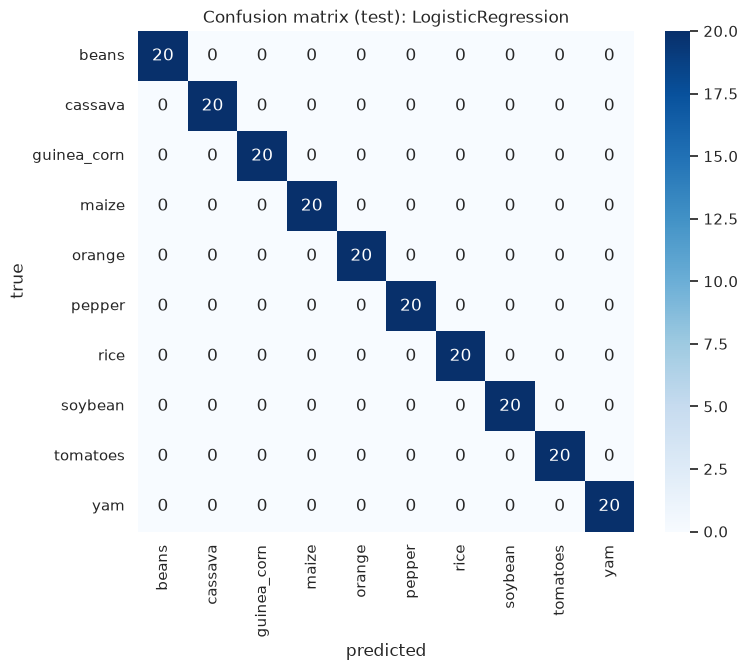

In [16]:
final_model = fitted[SELECTED]
test_proba = final_model.predict_proba(X_test)
test_pred = test_proba.argmax(axis=1)

report_txt = classification_report(y_test, test_pred, target_names=CLASSES, digits=4, zero_division=0)
print(report_txt)

cm = confusion_matrix(y_test, test_pred, labels=LABELS)
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, ax=ax)
ax.set(title=f"Confusion matrix (test): {SELECTED}", xlabel="predicted", ylabel="true")
save_fig(fig, "12_confusion_matrix_selected")
plt.show()

count    200.0000
mean       0.9688
std        0.0373
min        0.6477
5%         0.9090
25%        0.9608
50%        0.9790
max        0.9993
dtype: float64


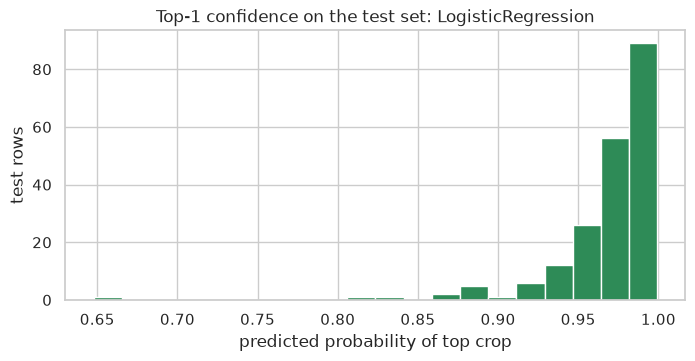

In [17]:
# Confidence the model assigns to its top prediction. Useful for interpreting the app's confidence scores.
top1_conf = test_proba.max(axis=1)
print(pd.Series(top1_conf).describe(percentiles=[0.05, 0.25, 0.5]).round(4))
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(top1_conf, bins=20, color="seagreen")
ax.set(title=f"Top-1 confidence on the test set: {SELECTED}", xlabel="predicted probability of top crop", ylabel="test rows")
save_fig(fig, "13_confidence_selected")
plt.show()

**Permutation importance** (on the test set, original 8 inputs): how much macro-F1 drops when one input is shuffled.
Phase 2 found that soil maps perfectly to crop groups, and this shows how much the selected model relies on it.

,importance_mean,importance_std
soil,0.1628,0.0185
N,0.1412,0.0205
K,0.1321,0.0162
rainfall,0.1175,0.0165
P,0.0672,0.0116
temperature,0.0364,0.0094
humidity,0.0169,0.0072
ph,0.0145,0.0085


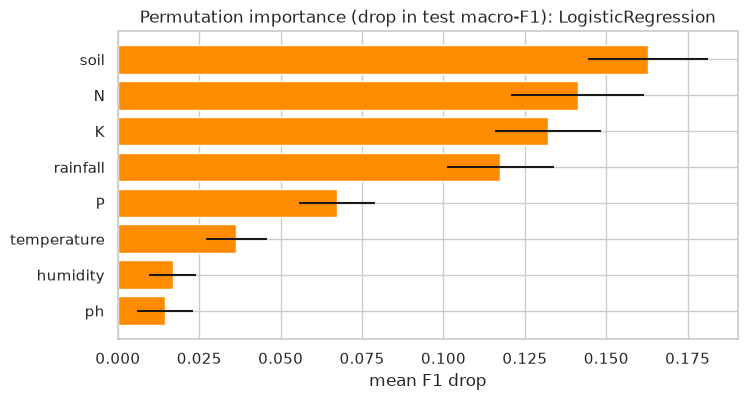

In [18]:
perm = permutation_importance(final_model, X_test, y_test, scoring="f1_macro", n_repeats=20,
                              random_state=RANDOM_STATE, n_jobs=-1)
importance = pd.DataFrame({"importance_mean": perm.importances_mean, "importance_std": perm.importances_std},
                          index=FEATURES).sort_values("importance_mean", ascending=False)
display(importance)
importance.to_csv(REPORTS_DIR / "feature_importance_selected.csv")

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(importance.index, importance["importance_mean"], xerr=importance["importance_std"], color="darkorange")
ax.invert_yaxis()
ax.set(title=f"Permutation importance (drop in test macro-F1): {SELECTED}", xlabel="mean F1 drop")
save_fig(fig, "14_permutation_importance_selected")
plt.show()

## 10. Serialize model & save logs
| File | Contents |
|---|---|
| `models/crop_model.joblib` | Full fitted pipeline (preprocessor + model), trained on the 800 training rows |
| `models/label_encoder.joblib` | Maps class indices ↔ crop names |
| `models/metadata.json` | Features, classes, valid input ranges, metrics, cost, parameters, library versions, seed |
| `reports/model_comparison.csv` | All candidates: CV, test, cost, robustness |
| `reports/cv_results.csv` | Full CV metrics (mean ± std) |
| `reports/evaluation_log.json` | Selection rule, shortlist, rationale, tuning log, classification report |
| `reports/figures/10–14_*.png` | Comparison and diagnostic figures |

The model is saved as trained on the training split, which is exactly the object evaluated above. Retraining on
all 1,000 rows is left to the Phase 4 `train.py` CLI as an option, so the reported test metrics stay tied to the
saved artifact.

In [19]:
MODEL_PATH = MODELS_DIR / "crop_model.joblib"
ENCODER_PATH = MODELS_DIR / "label_encoder.joblib"
joblib.dump(final_model, MODEL_PATH, compress=3)
joblib.dump(label_encoder, ENCODER_PATH)

def jsonable(d: dict) -> dict:
    return {k: (v.item() if hasattr(v, "item") else v) for k, v in d.items()}

versions = {"python": platform.python_version(), "scikit-learn": sklearn.__version__, "numpy": np.__version__,
            "pandas": pd.__version__, "joblib": joblib.__version__}
if xgb: versions["xgboost"] = xgb.__version__
if lgb: versions["lightgbm"] = lgb.__version__

model_params = {k: v for k, v in final_model.named_steps["model"].get_params().items()
                if isinstance(v, (int, float, str, bool, type(None)))}
metadata = {
    "model_name": SELECTED,
    "estimator_class": type(final_model.named_steps["model"]).__name__,
    "created_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "artifacts": {"model": MODEL_PATH.name, "label_encoder": ENCODER_PATH.name},
    "features": {"numeric": NUMERIC_FEATURES, "categorical": CATEGORICAL_FEATURES, "order": FEATURES},
    "soil_categories": prep_summary["soil_categories"],
    "classes": CLASSES,
    "feature_ranges": prep_summary["feature_ranges"],
    "training_data": {"source": "data/processed/train.csv", "rows": int(len(X_train)), "random_state": RANDOM_STATE},
    "cv_metrics": jsonable(comparison.loc[SELECTED, [c for c in comparison if c.startswith("cv_")]].to_dict()),
    "test_metrics": jsonable(comparison.loc[SELECTED, [c for c in comparison if c.startswith("test_")]].to_dict()),
    "cost": jsonable(cost_results.loc[SELECTED].to_dict()),
    "robustness": jsonable(robust_results.loc[SELECTED].to_dict()),
    "model_params": jsonable(model_params),
    "library_versions": versions,
    "candidates_evaluated": list(all_pipelines),
    "candidates_missing": missing,
}
(MODELS_DIR / "metadata.json").write_text(json.dumps(metadata, indent=2))

evaluation_log = {
    "created_utc": metadata["created_utc"],
    "selection_rule": "Highest CV macro-F1; models within 1 pp shortlisted; noise (10%) and log-loss (<=0.15) guards; "
                      "lowest summed cost rank (single-row latency, size, peak memory); ties -> lower CV log loss.",
    "best_cv_f1": float(best_cv_f1),
    "shortlist": shortlist.index.tolist(),
    "eligible_after_guards": eligible.index.tolist(),
    "selected": SELECTED,
    "rationale": rationale,
    "tuning": tuning_df.reset_index().to_dict(orient="records"),
    "classification_report_test": classification_report(y_test, test_pred, target_names=CLASSES, output_dict=True,
                                                        zero_division=0),
    "confusion_matrix_test": cm.tolist(),
    "machine": {"platform": platform.platform(), "cpu_count": os.cpu_count()},
}
(REPORTS_DIR / "evaluation_log.json").write_text(json.dumps(evaluation_log, indent=2, default=str))

for p in [MODEL_PATH, ENCODER_PATH, MODELS_DIR / "metadata.json", REPORTS_DIR / "model_comparison.csv",
          REPORTS_DIR / "cv_results.csv", REPORTS_DIR / "evaluation_log.json"]:
    print(f"{p.relative_to(PROJECT_ROOT)}  ({p.stat().st_size / 1024:.1f} KB)")

models/crop_model.joblib  (2.9 KB)
models/label_encoder.joblib  (0.7 KB)
models/metadata.json  (3.0 KB)
reports/model_comparison.csv  (4.6 KB)
reports/cv_results.csv  (2.3 KB)
reports/evaluation_log.json  (5.1 KB)


### Smoke test: reload the saved artifacts and produce a top-3 recommendation
This is what the app will do in Phase 5 (Phase 4 wraps it in `src/inference.py`).

In [20]:
loaded_model = joblib.load(MODEL_PATH)
loaded_encoder = joblib.load(ENCODER_PATH)
sample = pd.DataFrame([{"N": 90, "P": 42, "K": 43, "temperature": 26.5, "humidity": 80, "ph": 6.5,
                        "rainfall": 120, "soil": "loamy"}])  # example values from data/data_dictionary.csv
proba = loaded_model.predict_proba(sample)[0]
top3 = np.argsort(proba)[::-1][:3]
for rank, idx in enumerate(top3, 1):
    print(f"{rank}. {loaded_encoder.inverse_transform([idx])[0]:<12} confidence = {proba[idx]:.3f}")
assert np.allclose(loaded_model.predict_proba(X_test), test_proba)  # reloaded model is identical

1. rice         confidence = 0.442
2. pepper       confidence = 0.255
3. maize        confidence = 0.136


## 11. Summary
The selected model, its scores and the full rationale are printed in Section 8 and saved to
`reports/evaluation_log.json`. They are also recorded in `docs/phase_logs.md`.

**Key points**
- All real models far exceed the baseline, and most reach CV macro-F1 ≈ 1.0, as Phase 2 predicted.
- Since accuracy ties, the plan's cost rule decided, with quality guards on noise robustness and log loss.
- Every candidate reaches top-3 accuracy ≈ 1.0, so the app's top-3 list practically always contains the right crop
  *for data like the training set*.
- **Limitation (carried from Phase 2):** the dataset pairs each crop with exactly one soil type, and the model leans on
  that (see permutation importance). Real-world performance would be lower, and the app will say so.

**Next (Phase 4, after approval):** move this logic into modular `src/` scripts (`train.py` reproduces this model)
with tests.